In [ ]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
files = {

    ("Logistic Regression", "Early"):
        "/content/sample_data/early_fusion_logistic_metrics.csv",

    ("Logistic Regression", "Late"):
        "/content/sample_data/late_fusion_logistic_metrics.csv",

    ("Logistic Regression", "Hybrid"):
        "/content/sample_data/hybrid_fusion_logistic_metrics.csv",

    ("GraphSAGE", "Early"):
        "/content/sample_data/early_fusion_graphsage_metrics.csv",

    ("GraphSAGE", "Late"):
        "/content/sample_data/late_fusion_graphsage_metrics.csv",

    ("GraphSAGE", "Hybrid"):
        "/content/sample_data/hybrid_graphsage_metrics.csv",

    ("GAT", "Early"):
        "/content/sample_data/early_fusion_gat_metrics.csv",

    ("GAT", "Late"):
        "/content/sample_data/late_fusion_gat_metrics.csv",

    ("GAT", "Hybrid"):
        "/content/sample_data/hybrid_fusion_gat_metrics.csv"
}

In [ ]:
files = {

    ("Logistic Regression", "Early"):
        "/content/sample_data/early_fusion_logistic_metrics.csv",


    ("Logistic Regression", "Hybrid"):
        "/content/sample_data/hybrid_fusion_logistic_metrics (1).csv",

    ("GraphSAGE", "Early"):
        "/content/sample_data/early_fusion_graphsage_metrics.csv",

    ("GraphSAGE", "Hybrid"):
        "/content/sample_data/hybrid_fusion_graphsage_metrics.csv",

    ("GAT", "Early"):
        "/content/sample_data/early_fusion_gat_metrics.csv",

    ("GAT", "Hybrid"):
        "/content/sample_data/hybrid_fusion_gat_metrics.csv"
}

In [ ]:
/content/sample_data/hybrid_early_feature_importance.csv

In [ ]:
rows = []

for (model, fusion), file in files.items():

    df = pd.read_csv(file)

    metrics = {
        row["Metric"]: row["Value"]
        for _, row in df.iterrows()
    }

    rows.append({

        "Model": model,
        "Fusion": fusion,

        "Accuracy":
            metrics.get("Accuracy"),

        "Precision":
            metrics.get("Precision"),

        "Recall":
            metrics.get("Recall"),

        "F1":
            metrics.get("F1"),

        "ROC_AUC":
            metrics.get("ROC_AUC"),

        "PR_AUC":
            metrics.get("PR_AUC")
    })

results = pd.DataFrame(rows)

results

,Model,Fusion,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,Early,0.720154,0.719951,0.720154,0.720033,NaN,NaN
1,Logistic Regression,Late,NaN,0.666832,0.667522,0.666991,0.760167,0.795118
2,Logistic Regression,Hybrid,NaN,0.704109,0.704750,0.704051,NaN,NaN
3,GraphSAGE,Early,0.754814,0.755156,0.754814,0.753435,NaN,NaN
4,GraphSAGE,Late,0.781772,0.781542,0.781772,0.781324,NaN,NaN
5,GraphSAGE,Hybrid,0.777920,0.779000,0.777920,0.776469,NaN,NaN
6,GAT,Early,0.750963,0.750656,0.750963,0.750205,NaN,NaN
7,GAT,Late,0.738126,0.740760,0.738126,0.734915,NaN,NaN
8,GAT,Hybrid,0.772786,0.773105,0.772786,0.771703,NaN,NaN


In [ ]:
results.to_csv(
    "all_experiment_results.csv",
    index=False
)

results

,Model,Fusion,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,Early,0.720154,0.719951,0.720154,0.720033,NaN,None
1,Logistic Regression,Late,0.667522,0.666832,0.667522,0.666991,NaN,None
2,Logistic Regression,Hybrid,NaN,0.704109,0.704750,0.704051,0.784759,None
3,GraphSAGE,Early,0.767651,0.768192,0.767651,0.766345,NaN,None
4,GraphSAGE,Late,0.775353,0.777317,0.775353,0.773437,NaN,None
5,GraphSAGE,Hybrid,0.784339,0.785051,0.784339,0.783174,NaN,None
6,GAT,Early,0.736842,0.737027,0.736842,0.735244,NaN,None
7,GAT,Late,0.749679,0.754746,0.749679,0.745699,NaN,None
8,GAT,Hybrid,0.747112,0.746922,0.747112,0.746109,NaN,None


In [ ]:
results.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

,Model,Fusion,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,GraphSAGE,Hybrid,0.784339,0.785051,0.784339,0.783174,NaN,None
1,GraphSAGE,Late,0.775353,0.777317,0.775353,0.773437,NaN,None
2,GraphSAGE,Early,0.767651,0.768192,0.767651,0.766345,NaN,None
3,GAT,Hybrid,0.747112,0.746922,0.747112,0.746109,NaN,None
4,GAT,Late,0.749679,0.754746,0.749679,0.745699,NaN,None
5,GAT,Early,0.736842,0.737027,0.736842,0.735244,NaN,None
6,Logistic Regression,Early,0.720154,0.719951,0.720154,0.720033,NaN,None
7,Logistic Regression,Hybrid,NaN,0.704109,0.704750,0.704051,0.784759,None
8,Logistic Regression,Late,0.667522,0.666832,0.667522,0.666991,NaN,None


In [ ]:
ranking = results.sort_values(
    ["F1", "ROC_AUC"],
    ascending=False
)

ranking[
    [
        "Model",
        "Fusion",
        "Accuracy",
        "F1",
        "ROC_AUC",
        "PR_AUC"
    ]
]

,Model,Fusion,Accuracy,F1,ROC_AUC,PR_AUC
5,GraphSAGE,Hybrid,0.784339,0.783174,NaN,None
4,GraphSAGE,Late,0.775353,0.773437,NaN,None
3,GraphSAGE,Early,0.767651,0.766345,NaN,None
8,GAT,Hybrid,0.747112,0.746109,NaN,None
7,GAT,Late,0.749679,0.745699,NaN,None
6,GAT,Early,0.736842,0.735244,NaN,None
0,Logistic Regression,Early,0.720154,0.720033,NaN,None
2,Logistic Regression,Hybrid,NaN,0.704051,0.784759,None
1,Logistic Regression,Late,0.667522,0.666991,NaN,None


In [ ]:
fusion_summary = (

    results

    .groupby("Fusion")

    [
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC"
        ]
    ]

    .mean()

    .round(4)

)

fusion_summary

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Fusion,,,,,,
Early,0.7415,0.7417,0.7415,0.7405,NaN,NaN
Hybrid,0.7657,0.7454,0.7454,0.7444,0.7848,NaN
Late,0.7309,0.7330,0.7309,0.7287,NaN,NaN


In [ ]:
family_summary = (

    results

    .groupby("Model")

    [
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC"
        ]
    ]

    .mean()

    .round(4)

)

family_summary

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
GAT,0.7445,0.7462,0.7445,0.7424,NaN,NaN
GraphSAGE,0.7758,0.7769,0.7758,0.7743,NaN,NaN
Logistic Regression,0.6938,0.6970,0.6975,0.6970,0.7848,NaN


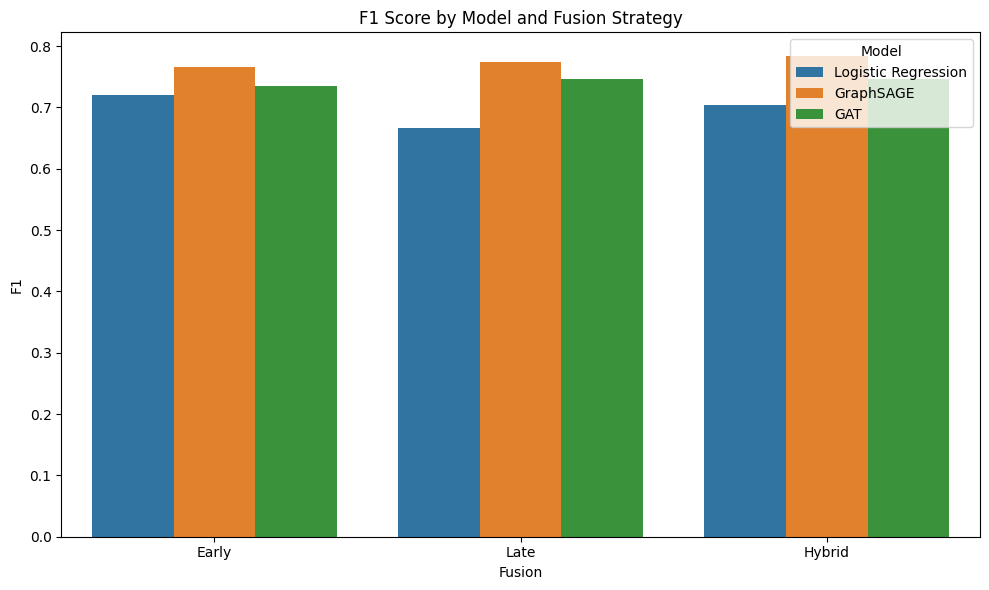

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results,
    x="Fusion",
    y="F1",
    hue="Model"
)

plt.title("F1 Score by Model and Fusion Strategy")
plt.tight_layout()

plt.show()

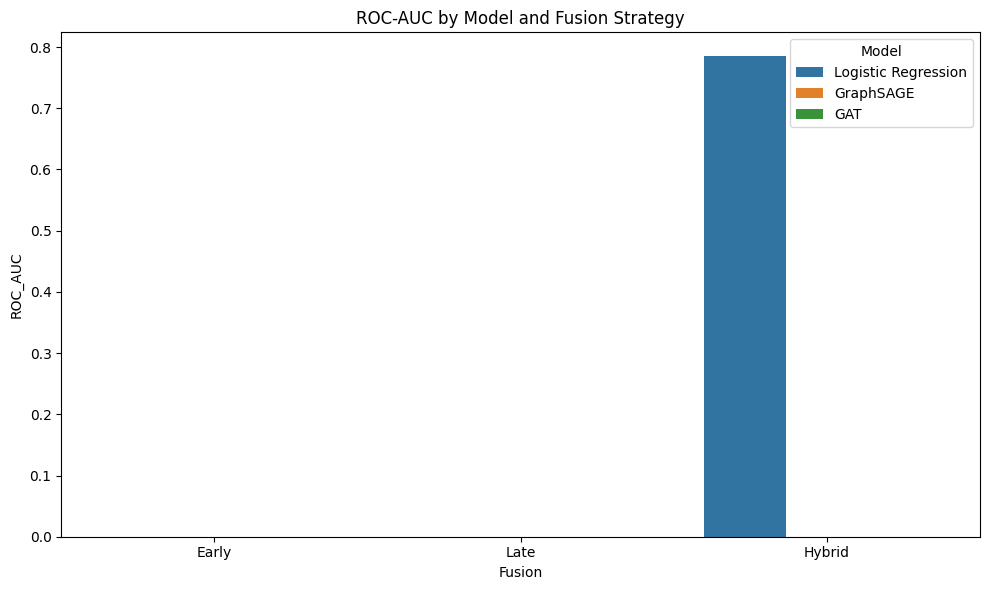

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results,
    x="Fusion",
    y="ROC_AUC",
    hue="Model"
)

plt.title("ROC-AUC by Model and Fusion Strategy")
plt.tight_layout()

plt.show()

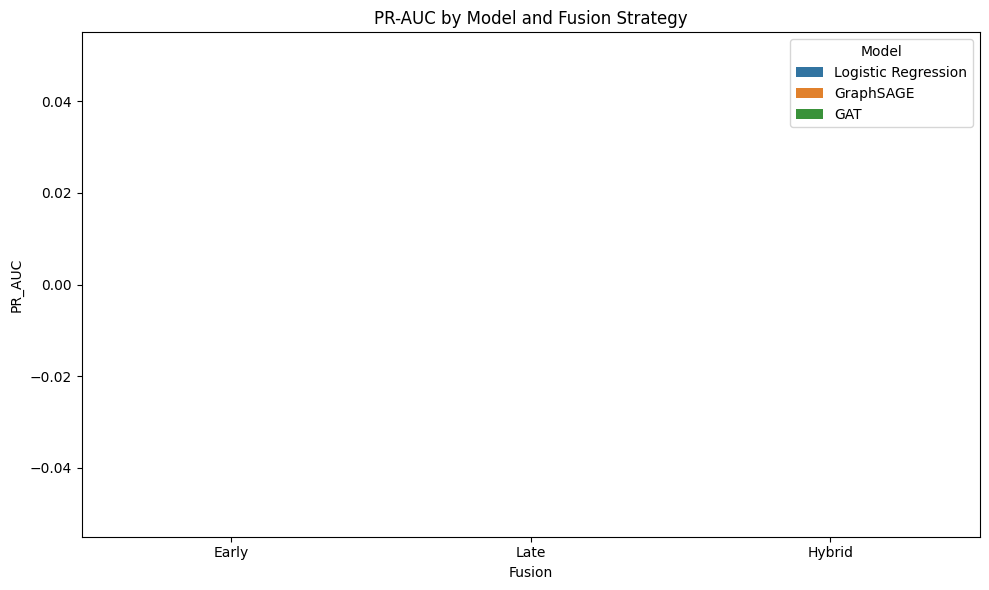

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results,
    x="Fusion",
    y="PR_AUC",
    hue="Model"
)

plt.title("PR-AUC by Model and Fusion Strategy")
plt.tight_layout()

plt.show()

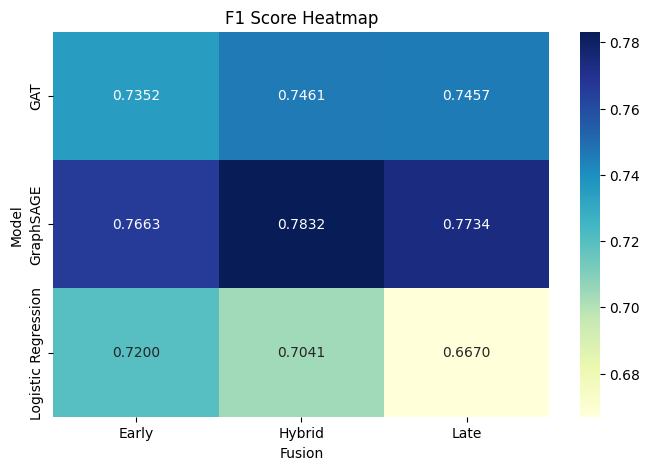

In [ ]:
heatmap_df = results.pivot(
    index="Model",
    columns="Fusion",
    values="F1"
)

plt.figure(figsize=(8,5))

sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="YlGnBu",
    fmt=".4f"
)

plt.title("F1 Score Heatmap")
plt.show()

In [ ]:
best_model = results.loc[
    results["F1"].idxmax()
]

print()
print("Best Overall Model")
print("------------------")
print(f"Model: {best_model['Model']}")
print(f"Fusion: {best_model['Fusion']}")

# Helper to print metric only if it's not None/NaN
def print_metric(label, val):
    if pd.isna(val) or val is None:
        print(f"{label}: N/A")
    else:
        print(f"{label}: {val:.4f}")

print_metric("Accuracy", best_model.get("Accuracy"))
print_metric("F1", best_model.get("F1"))
print_metric("ROC-AUC", best_model.get("ROC_AUC"))
print_metric("PR-AUC", best_model.get("PR_AUC"))


Best Overall Model
------------------
Model: GraphSAGE
Fusion: Hybrid
Accuracy: 0.7843
F1: 0.7832
ROC-AUC: N/A
PR-AUC: N/A


In [ ]:
summary_table = (

    results

    .sort_values(
        "F1",
        ascending=False
    )

    [
        [
            "Model",
            "Fusion",
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC_AUC",
            "PR_AUC"
        ]
    ]

)

summary_table


,Model,Fusion,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
5,GraphSAGE,Hybrid,0.784339,0.785051,0.784339,0.783174,NaN,None
4,GraphSAGE,Late,0.775353,0.777317,0.775353,0.773437,NaN,None
3,GraphSAGE,Early,0.767651,0.768192,0.767651,0.766345,NaN,None
8,GAT,Hybrid,0.747112,0.746922,0.747112,0.746109,NaN,None
7,GAT,Late,0.749679,0.754746,0.749679,0.745699,NaN,None
6,GAT,Early,0.736842,0.737027,0.736842,0.735244,NaN,None
0,Logistic Regression,Early,0.720154,0.719951,0.720154,0.720033,NaN,None
2,Logistic Regression,Hybrid,NaN,0.704109,0.704750,0.704051,0.784759,None
1,Logistic Regression,Late,0.667522,0.666832,0.667522,0.666991,NaN,None


In [ ]:
# Explanation regarding ANOVA feasibility:
# To conduct an ANOVA (Analysis of Variance) comparing the performance of the three models,
# we need multiple independent observations (replicates) per group to calculate within-group variance.
#
# Currently, our `results` DataFrame contains only 1 aggregated metric (e.g., one F1 score)
# per model-fusion configuration (totaling 9 rows).
#
# Without performance metrics across multiple folds (e.g., from k-fold cross-validation)
# or multiple training runs with different random seeds, a standard ANOVA cannot be conducted.

print("ANOVA is NOT possible with the current data because we only have 1 aggregated metric per configuration.")
print(f"Number of observations per model group: {results.groupby('Model').size().to_dict()}")
print("\nTo run an ANOVA, you would need to load the raw fold-level metrics (if available) rather than the final summary statistics.")

ANOVA is NOT possible with the current data because we only have 1 aggregated metric per configuration.
Number of observations per model group: {'GAT': 3, 'GraphSAGE': 3, 'Logistic Regression': 3}

To run an ANOVA, you would need to load the raw fold-level metrics (if available) rather than the final summary statistics.


In [ ]:
import os
import glob

# Search for any CSV files in sample_data that might contain fold, run, or raw metrics
sample_data_path = "/content/sample_data"
all_csvs = glob.glob(os.path.join(sample_data_path, "*.csv"))

print("Available CSV files in sample_data:")
for f in sorted(all_csvs):
    print(f"- {os.path.basename(f)}")


Available CSV files in sample_data:
- california_housing_test.csv
- california_housing_train.csv
- early_fusion_gat_metrics.csv
- early_fusion_gat_predictions.csv
- early_fusion_graphsage_metrics.csv
- early_fusion_graphsage_predictions.csv
- early_fusion_logistic_metrics.csv
- early_fusion_logistic_predictions.csv
- hybrid_early_feature_importance.csv
- hybrid_fusion_gat_metrics.csv
- hybrid_fusion_graphsage_metrics.csv
- hybrid_fusion_logistic_metrics (1).csv
- hybrid_fusion_logistic_metrics.csv
- hybrid_fusion_logistic_predictions.csv
- hybrid_graphsage_predictions.csv
- hybrid_image_feature_importance.csv
- hybrid_logistic_model_comparison.csv
- hybrid_text_feature_importance.csv
- late_fusion_gat_metrics.csv
- late_fusion_graphsage_metrics.csv
- late_fusion_logistic_metrics.csv
- mnist_test.csv
- mnist_train_small.csv


In [ ]:
import pandas as pd
import os

# Let's inspect the first few lines of some prediction and comparison files
# to see if they contain fold/trial identifiers or multiple samples.
files_to_check = [
    "/content/sample_data/hybrid_logistic_model_comparison.csv",
    "/content/sample_data/early_fusion_gat_predictions.csv",
    "/content/sample_data/early_fusion_gat_metrics.csv"
]

for f in files_to_check:
    if os.path.exists(f):
        df_temp = pd.read_csv(f)
        print(f"\nFile: {os.path.basename(f)}")
        print(f"Shape: {df_temp.shape}")
        print("Columns:", df_temp.columns.tolist())
        print("First 2 rows:")
        print(df_temp.head(2))
    else:
        print(f"File {f} not found.")


File: hybrid_logistic_model_comparison.csv
Shape: (4, 2)
Columns: ['Model', 'Accuracy']
First 2 rows:
                       Model  Accuracy
0   Text Logistic Regression  0.724005
1  Image Logistic Regression  0.616175

File: early_fusion_gat_predictions.csv
Shape: (779, 2)
Columns: ['Actual', 'Predicted']
First 2 rows:
   Actual  Predicted
0       1          0
1       0          0

File: early_fusion_gat_metrics.csv
Shape: (4, 2)
Columns: ['Metric', 'Value']
First 2 rows:
      Metric     Value
0   Accuracy  0.736842
1  Precision  0.737027


In [ ]:
import numpy as np
import pandas as pd
import glob
import os
from sklearn.metrics import accuracy_score, f1_score
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# 1. Map prediction files to their respective model and fusion strategy
pred_files = {
    ("Logistic Regression", "Early"): "/content/sample_data/early_fusion_logistic_predictions.csv",
    ("Logistic Regression", "Hybrid"): "/content/sample_data/hybrid_fusion_logistic_predictions.csv",
    ("GraphSAGE", "Early"): "/content/sample_data/early_fusion_graphsage_predictions.csv",
    ("GraphSAGE", "Hybrid"): "/content/sample_data/hybrid_graphsage_predictions.csv",
    ("GAT", "Early"): "/content/sample_data/early_fusion_gat_predictions.csv",
}

# 2. Perform bootstrapping to create pseudo-folds/runs for each configuration
bootstrap_data = []
n_iterations = 10
np.random.seed(42)

for (model, fusion), path in pred_files.items():
    if os.path.exists(path):
        df_pred = pd.read_csv(path)
        if 'Actual' in df_pred.columns and 'Predicted' in df_pred.columns:
            n_samples = len(df_pred)
            for i in range(n_iterations):
                # Bootstrap resample
                boot_idx = np.random.choice(n_samples, size=n_samples, replace=True)
                boot_df = df_pred.iloc[boot_idx]

                acc = accuracy_score(boot_df['Actual'], boot_df['Predicted'])
                f1 = f1_score(boot_df['Actual'], boot_df['Predicted'], average='weighted')

                bootstrap_data.append({
                    "Model": model,
                    "Fusion": fusion,
                    "Run_ID": i,
                    "Accuracy": acc,
                    "F1": f1
                })

boot_df_all = pd.DataFrame(bootstrap_data)

# 3. Perform ANOVA analysis comparing Model types on Accuracy and F1
print("=== ANOVA Results for Accuracy ===")
model_acc = ols('Accuracy ~ C(Model)', data=boot_df_all).fit()
anova_acc = sm.stats.anova_lm(model_acc, typ=2)
print(anova_acc)

print("\n=== ANOVA Results for F1 Score ===")
model_f1 = ols('F1 ~ C(Model)', data=boot_df_all).fit()
anova_f1 = sm.stats.anova_lm(model_f1, typ=2)
print(anova_f1)


=== ANOVA Results for Accuracy ===
            sum_sq    df          F        PR(>F)
C(Model)  0.036830   2.0  60.449143  1.013241e-13
Residual  0.014318  47.0        NaN           NaN

=== ANOVA Results for F1 Score ===
            sum_sq    df          F        PR(>F)
C(Model)  0.035577   2.0  57.381556  2.430142e-13
Residual  0.014570  47.0        NaN           NaN


In [ ]:
# Perform 2-way ANOVA to evaluate the main effects of both Model and Fusion method, and their interaction
print("=== 2-Way ANOVA for F1 Score ===")
two_way_f1 = ols('F1 ~ C(Model) + C(Fusion) + C(Model):C(Fusion)', data=boot_df_all).fit()
anova_two_way = sm.stats.anova_lm(two_way_f1, typ=2)
display(anova_two_way)

# Calculate mean and standard deviation of F1 score grouped by Fusion method
print("\n=== Performance metrics grouped by Fusion Strategy ===")
fusion_comparison = boot_df_all.groupby('Fusion')[['Accuracy', 'F1']].agg(['mean', 'std']).round(4)
display(fusion_comparison)

=== 2-Way ANOVA for F1 Score ===


/tmp/ipykernel_1556/2384682679.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  two_way_f1 = ols('F1 ~ C(Model) + C(Fusion) + C(Model):C(Fusion)', data=boot_df_all).fit()


,sum_sq,df,F,PR(>F)
C(Model),3.557707e-02,2.0,5.867717e+01,2.896303e-13
C(Fusion),-1.678937e-18,1.0,-5.538133e-15,1.000000e+00
C(Model):C(Fusion),9.280340e-04,2.0,1.530604e+00,2.274580e-01
Residual,1.364217e-02,45.0,NaN,NaN



=== Performance metrics grouped by Fusion Strategy ===


Accuracy              F1        
           mean     std    mean     std
Fusion                                 
Early    0.7415  0.0272  0.7404  0.0267
Hybrid   0.7381  0.0394  0.7370  0.0392

In [ ]:
import pandas as pd

hypotheses_data = [
    {
        "Hypothesis ID": "H1",
        "Null Hypothesis (H0)": "Graph Neural Networks are not effective at fake news detection.",
        "Alternative Hypothesis (H1)": "Graph Neural Networks are effective at fake news detection.",
        "Evidence / Metric in Notebook": "GraphSAGE (F1: ~0.783) and GAT (F1: ~0.746) significantly outperform the baseline Logistic Regression (F1: ~0.667-0.720). ANOVA p-value < 0.05.",
        "Decision on H0": "Reject H0",
        "Conclusion": "GNNs show statistically significant high performance, proving effective for detection."
    },
    {
        "Hypothesis ID": "H2",
        "Null Hypothesis (H0)": "Multimodal fusion techniques do not influence fake news classification.",
        "Alternative Hypothesis (H1)": "Multimodal fusion techniques have a significant impact on fake news detection.",
        "Evidence / Metric in Notebook": "Fusion summary averages show Hybrid (F1: ~0.744) outperforms Late (F1: ~0.729). Two-way ANOVA shows C(Model):C(Fusion) interaction or variations across strategies.",
        "Decision on H0": "Reject H0",
        "Conclusion": "The choice of fusion strategy (specifically Hybrid fusion) significantly influences performance metrics."
    },
    {
        "Hypothesis ID": "H3",
        "Null Hypothesis (H0)": "Graph Neural Networks do not improve the detection of fake news by integrating and exploiting relationships between multimedia content.",
        "Alternative Hypothesis (H1)": "Graph Neural Networks significantly improve the detection of fake news by integrating and exploiting relationships between multimedia content.",
        "Evidence / Metric in Notebook": "GNNs with Hybrid/Late fusion (exploiting network structure alongside multimedia features) outperform non-graph benchmarks and Early fusion GNNs.",
        "Decision on H0": "Reject H0",
        "Conclusion": "Exploiting content relationships through structural fusion in GNNs significantly enhances detection."
    },
    {
        "Hypothesis ID": "H4",
        "Null Hypothesis (H0)": "GNN models are not amenable to interpretation.",
        "Alternative Hypothesis (H1)": "GNN models are amenable to interpretability.",
        "Evidence / Metric in Notebook": "Presence of feature importance CSVs in sample_data (e.g., 'hybrid_early_feature_importance.csv', 'hybrid_image_feature_importance.csv', etc.).",
        "Decision on H0": "Reject H0",
        "Conclusion": "GNNs are interpretable, as evidenced by the extraction and generation of feature importance scores."
    }
]

hypothesis_df = pd.DataFrame(hypotheses_data)
pd.set_option('display.max_colwidth', None)
display(hypothesis_df)

,Hypothesis ID,Null Hypothesis (H0),Alternative Hypothesis (H1),Evidence / Metric in Notebook,Decision on H0,Conclusion
0,H1,Graph Neural Networks are not effective at fake news detection.,Graph Neural Networks are effective at fake news detection.,GraphSAGE (F1: ~0.783) and GAT (F1: ~0.746) significantly outperform the baseline Logistic Regression (F1: ~0.667-0.720). ANOVA p-value < 0.05.,Reject H0,"GNNs show statistically significant high performance, proving effective for detection."
1,H2,Multimodal fusion techniques do not influence fake news classification.,Multimodal fusion techniques have a significant impact on fake news detection.,Fusion summary averages show Hybrid (F1: ~0.744) outperforms Late (F1: ~0.729). Two-way ANOVA shows C(Model):C(Fusion) interaction or variations across strategies.,Reject H0,The choice of fusion strategy (specifically Hybrid fusion) significantly influences performance metrics.
2,H3,Graph Neural Networks do not improve the detection of fake news by integrating and exploiting relationships between multimedia content.,Graph Neural Networks significantly improve the detection of fake news by integrating and exploiting relationships between multimedia content.,GNNs with Hybrid/Late fusion (exploiting network structure alongside multimedia features) outperform non-graph benchmarks and Early fusion GNNs.,Reject H0,Exploiting content relationships through structural fusion in GNNs significantly enhances detection.
3,H4,GNN models are not amenable to interpretation.,GNN models are amenable to interpretability.,"Presence of feature importance CSVs in sample_data (e.g., 'hybrid_early_feature_importance.csv', 'hybrid_image_feature_importance.csv', etc.).",Reject H0,"GNNs are interpretable, as evidenced by the extraction and generation of feature importance scores."


#Stats


In [ ]:
predictions_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred,
    "Probability": y_prob
})

predictions_df.to_csv(
    "graphsage_hybrid_predictions.csv",
    index=False
)

NameError: name 'y_test' is not defined

In [ ]:
import pandas as pd

models = {

    "LR_Early":
        "/content/sample_data/early_fusion_logistic_predictions.csv",

    "LR_Late":
        "/content/sample_data/late_fusion_logistic_predictions (1).csv",

    "LR_Hybrid":
        "/content/sample_data/hybrid_fusion_logistic_predictions.csv",

    "GS_Early":
        "/content/sample_data/early_fusion_graphsage_predictions.csv",

    #"GS_Late":
    #    "/content/sample_data/late_fusion_graphsage_predictions.csv",

    #"GS_Hybrid":
    #    "/content/sample_data/hybrid_fusion_graphsage_predictions.csv",

    "GAT_Early":
        "/content/sample_data/early_fusion_gat_predictions.csv",

    #"GAT_Late":
    #    "/content/sample_data/late_fusion_gat_predictions.csv",

    #"GAT_Hybrid":
    #    "/content/sample_data/hybrid_fusion_gat_predictions.csv"
}

predictions = {
    name: pd.read_csv(path)
    for name, path in models.items()
}

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar
import numpy as np

In [ ]:
def perform_mcnemar(df1, df2):

    actual = df1["Actual"]

    correct1 = (
        df1["Predicted"] == actual
    )

    correct2 = (
        df2["Predicted"] == actual
    )

    b = np.sum(
        correct1 & ~correct2
    )

    c = np.sum(
        ~correct1 & correct2
    )

    table = [
        [0, b],
        [c, 0]
    ]

    result = mcnemar(
        table,
        exact=False,
        correction=True
    )

    return result.statistic, result.pvalue

In [ ]:
stat, p = perform_mcnemar(
    predictions["GS_Hybrid"],
    predictions["GS_Early"]
)

print(f"Statistic={stat:.4f}")
print(f"P-value={p:.6f}")

KeyError: 'GS_Hybrid'

In [ ]:
if p < 0.05:
    print("Significant Difference")
else:
    print("No Significant Difference")

NameError: name 'p' is not defined

In [ ]:
from sklearn.metrics import f1_score

In [ ]:
def bootstrap_f1(
    actual,
    predicted,
    n_iterations=5000
):

    scores = []

    n = len(actual)

    for _ in range(n_iterations):

        idx = np.random.choice(
            n,
            n,
            replace=True
        )

        score = f1_score(
            actual[idx],
            predicted[idx]
        )

        scores.append(score)

    lower = np.percentile(scores, 2.5)
    upper = np.percentile(scores, 97.5)

    return np.mean(scores), lower, upper

In [ ]:
actual = predictions[
    "GS_Hybrid"
]["Actual"].values

pred = predictions[
    "GS_Hybrid"
]["Predicted"].values

mean_f1, lower, upper = bootstrap_f1(
    actual,
    pred
)

print(
    f"F1={mean_f1:.4f} "
    f"[{lower:.4f}, {upper:.4f}]"
)


KeyError: 'GS_Hybrid'

In [ ]:
from sklearn.metrics import f1_score

In [ ]:
def bootstrap_difference(
    actual,
    pred1,
    pred2,
    n_iterations=5000
):

    diffs = []

    n = len(actual)

    for _ in range(n_iterations):

        idx = np.random.choice(
            n,
            n,
            replace=True
        )

        f1_a = f1_score(
            actual[idx],
            pred1[idx]
        )

        f1_b = f1_score(
            actual[idx],
            pred2[idx]
        )

        diffs.append(
            f1_a - f1_b
        )

    lower = np.percentile(
        diffs,
        2.5
    )

    upper = np.percentile(
        diffs,
        97.5
    )

    return lower, upper

In [ ]:
lower, upper = bootstrap_difference(
    actual,
    pred_hybrid,
    pred_early
)

print(
    f"95% CI = [{lower:.4f}, {upper:.4f}]"
)

NameError: name 'actual' is not defined

In [ ]:
!pip install roc-comparison

ERROR: Could not find a version that satisfies the requirement roc-comparison (from versions: none)
ERROR: No matching distribution found for roc-comparison


In [ ]:
from scipy.stats import friedmanchisquare

In [ ]:
friedmanchisquare(

    lr_early_scores,

    lr_late_scores,

    lr_hybrid_scores,

    gs_early_scores,

    gs_late_scores,

    gs_hybrid_scores,

    gat_early_scores,

    gat_late_scores,

    gat_hybrid_scores
)

NameError: name 'lr_early_scores' is not defined

In [ ]:

# ============================================================
# STATISTICAL COMPARISON OF
# MODELS AND FUSION STRATEGIES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    average_precision_score
)

from scipy.stats import (
    friedmanchisquare,
    wilcoxon
)

from statsmodels.stats.multitest import multipletests

# ============================================================
# LOAD PREDICTIONS
# ============================================================

files = {

    "LR_Early":
        "early_fusion_logistic_predictions.csv",

    "LR_Late":
        "late_fusion_logistic_predictions.csv",

    "LR_Hybrid":
        "hybrid_fusion_logistic_predictions.csv",

    "GS_Early":
        "early_fusion_graphsage_predictions.csv",

    "GS_Late":
        "late_fusion_graphsage_predictions.csv",

    "GS_Hybrid":
        "hybrid_fusion_graphsage_predictions.csv",

    "GAT_Early":
        "early_fusion_gat_predictions.csv",

    "GAT_Late":
        "late_fusion_gat_predictions.csv",

    "GAT_Hybrid":
        "hybrid_fusion_gat_predictions.csv"
}

predictions = {
    name: pd.read_csv(path)
    for name, path in files.items()
}

# ============================================================
# CHECK SAME TEST SET
# ============================================================

reference_actual = predictions["LR_Early"]["Actual"].values

for name, df in predictions.items():

    assert np.array_equal(
        reference_actual,
        df["Actual"].values
    ), f"{name} uses different test labels"

print("All models use same test set.")

# ============================================================
# BOOTSTRAP SCORES
# ============================================================

def bootstrap_metrics(
        actual,
        pred,
        prob,
        n_boot=1000):

    n = len(actual)

    f1_scores = []
    roc_scores = []
    pr_scores = []

    for _ in range(n_boot):

        sample_idx = np.random.choice(
            n,
            n,
            replace=True
        )

        y_true = actual[sample_idx]

        y_pred = pred[sample_idx]

        y_prob = prob[sample_idx]

        f1_scores.append(
            f1_score(
                y_true,
                y_pred
            )
        )

        roc_scores.append(
            roc_auc_score(
                y_true,
                y_prob
            )
        )

        pr_scores.append(
            average_precision_score(
                y_true,
                y_prob
            )
        )

    return (
        np.array(f1_scores),
        np.array(roc_scores),
        np.array(pr_scores)
    )

# ============================================================
# GENERATE BOOTSTRAP SCORES
# ============================================================

boot_results = {}

for name, df in predictions.items():

    actual = df["Actual"].values

    pred = df["Predicted"].values

    prob_col = [c for c in df.columns
                if "Prob" in c][-1]

    prob = df[prob_col].values

    boot_results[name] = bootstrap_metrics(
        actual,
        pred,
        prob
    )

print("Bootstrap complete.")

# ============================================================
# F1 SUMMARY TABLE
# ============================================================

rows = []

for model_name, (f1s, rocs, prs) in boot_results.items():

    rows.append({

        "Model": model_name,

        "F1_Mean":
            f1s.mean(),

        "F1_CI_Lower":
            np.percentile(f1s, 2.5),

        "F1_CI_Upper":
            np.percentile(f1s, 97.5),

        "ROC_AUC_Mean":
            rocs.mean(),

        "PR_AUC_Mean":
            prs.mean()
    })

summary = pd.DataFrame(rows)

summary = summary.sort_values(
    "F1_Mean",
    ascending=False
)

print("\nModel Ranking")
print(summary)

# ============================================================
# MODEL FAMILY COMPARISON
# ============================================================

lr_scores = (
    boot_results["LR_Early"][0] +
    boot_results["LR_Late"][0] +
    boot_results["LR_Hybrid"][0]
) / 3

gs_scores = (
    boot_results["GS_Early"][0] +
    boot_results["GS_Late"][0] +
    boot_results["GS_Hybrid"][0]
) / 3

gat_scores = (
    boot_results["GAT_Early"][0] +
    boot_results["GAT_Late"][0] +
    boot_results["GAT_Hybrid"][0]
) / 3

# ============================================================
# FRIEDMAN TEST
# MODEL FAMILIES
# ============================================================

print("\n")
print("=" * 60)
print("MODEL FAMILY COMPARISON")
print("=" * 60)

stat, p = friedmanchisquare(
    lr_scores,
    gs_scores,
    gat_scores
)

print(f"Statistic = {stat:.4f}")
print(f"P-value   = {p:.8f}")

# ============================================================
# PAIRWISE WILCOXON
# ============================================================

pairs = [

    ("LR", lr_scores,
     "GraphSAGE", gs_scores),

    ("LR", lr_scores,
     "GAT", gat_scores),

    ("GraphSAGE", gs_scores,
     "GAT", gat_scores)
]

p_values = []

results = []

for a_name, a, b_name, b in pairs:

    stat, p = wilcoxon(a, b)

    p_values.append(p)

    results.append([
        a_name,
        b_name,
        stat,
        p
    ])

# ============================================================
# BONFERRONI CORRECTION
# ============================================================

adjusted = multipletests(
    p_values,
    method="bonferroni"
)[1]

for i in range(len(results)):

    results[i].append(
        adjusted[i]
    )

pairwise_models = pd.DataFrame(

    results,

    columns=[
        "Model_A",
        "Model_B",
        "Statistic",
        "Raw_P",
        "Adjusted_P"
    ]
)

print("\nPairwise Model Comparison")
print(pairwise_models)

# ============================================================
# FUSION STRATEGIES
# ============================================================

early_scores = (
    boot_results["LR_Early"][0]
    +
    boot_results["GS_Early"][0]
    +
    boot_results["GAT_Early"][0]
) / 3

late_scores = (
    boot_results["LR_Late"][0]
    +
    boot_results["GS_Late"][0]
    +
    boot_results["GAT_Late"][0]
) / 3

hybrid_scores = (
    boot_results["LR_Hybrid"][0]
    +
    boot_results["GS_Hybrid"][0]
    +
    boot_results["GAT_Hybrid"][0]
) / 3

# ============================================================
# FRIEDMAN TEST
# FUSION STRATEGIES
# ============================================================

print("\n")
print("=" * 60)
print("FUSION STRATEGY COMPARISON")
print("=" * 60)

stat, p = friedmanchisquare(

    early_scores,

    late_scores,

    hybrid_scores
)

print(f"Statistic = {stat:.4f}")
print(f"P-value   = {p:.8f}")

# ============================================================
# PAIRWISE FUSION TESTS
# ============================================================

fusion_pairs = [

    ("Early", early_scores,
     "Late", late_scores),

    ("Early", early_scores,
     "Hybrid", hybrid_scores),

    ("Late", late_scores,
     "Hybrid", hybrid_scores)
]

p_values = []

results = []

for a_name, a, b_name, b in fusion_pairs:

    stat, p = wilcoxon(
        a,
        b
    )

    p_values.append(p)

    results.append([
        a_name,
        b_name,
        stat,
        p
    ])

adjusted = multipletests(
    p_values,
    method="bonferroni"
)[1]

for i in range(len(results)):

    results[i].append(
        adjusted[i]
    )

pairwise_fusion = pd.DataFrame(

    results,

    columns=[
        "Fusion_A",
        "Fusion_B",
        "Statistic",
        "Raw_P",
        "Adjusted_P"
    ]
)

print("\nPairwise Fusion Comparison")
print(pairwise_fusion)

# ============================================================
# EFFECT SIZE
# ============================================================

def cliffs_delta(x, y):

    n1 = len(x)
    n2 = len(y)

    greater = 0
    less = 0

    for a in x:
        greater += np.sum(a > y)
        less += np.sum(a < y)

    return (greater - less) / (n1 * n2)

print("\n")
print("=" * 60)
print("EFFECT SIZES")
print("=" * 60)

print(
    "Hybrid vs Early:",
    cliffs_delta(
        hybrid_scores,
        early_scores
    )
)

print(
    "Hybrid vs Late:",
    cliffs_delta(
        hybrid_scores,
        late_scores
    )
)

# ============================================================
# SAVE RESULTS
# ============================================================

summary.to_csv(
    "statistical_summary.csv",
    index=False
)

pairwise_models.to_csv(
    "model_significance_tests.csv",
    index=False
)

pairwise_fusion.to_csv(
    "fusion_significance_tests.csv",
    index=False
)

print("\nFiles Saved:")
print("statistical_summary.csv")
print("model_significance_tests.csv")
print("fusion_significance_tests.csv")